In [21]:
print("Program is developed by",u"\u092A\u094D\u0930\u093F\u092F\u093E\u0902\u0936\u0941\u0020\u092E\u093F\u0936\u094D\u0930\u093E")
print("Program is checked by",u"\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947")
print("Date of performance - 28 Jul 2026")

Program is developed by प्रियांशु मिश्रा
Program is checked by वैशाली इंगळे
Date of performance - 28 Jul 2026


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder as le, StandardScaler as ss
from sklearn.model_selection import train_test_split as tts

# Load Dataset

In [24]:
df= pd.read_csv("gender_classification_v7.csv")

In [25]:
df.head()

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,Male
1,0,14.0,5.4,0,0,1,0,Female
2,0,11.8,6.3,1,1,1,1,Male
3,0,14.4,6.1,0,1,1,1,Male
4,1,13.5,5.9,0,0,0,0,Female


# Dataset Information

In [27]:
print("Number of labels: ", df.shape[0])
print("Number of featues: ", df.shape[1])

Number of labels:  5001
Number of featues:  8


In [28]:
print("Featue Information:")
print("-" * 70)

for col in df.columns:
    print(
        f"Column: {col:<25} "
        f"Data Type: {str(df[col].dtype):<10} "
        f"Non-Null: {df[col].notnull().sum():<6}"
    )

print("-" * 70)

Featue Information:
----------------------------------------------------------------------
Column: long_hair                 Data Type: int64      Non-Null: 5001  
Column: forehead_width_cm         Data Type: float64    Non-Null: 5001  
Column: forehead_height_cm        Data Type: float64    Non-Null: 5001  
Column: nose_wide                 Data Type: int64      Non-Null: 5001  
Column: nose_long                 Data Type: int64      Non-Null: 5001  
Column: lips_thin                 Data Type: int64      Non-Null: 5001  
Column: distance_nose_to_lip_long Data Type: int64      Non-Null: 5001  
Column: gender                    Data Type: object     Non-Null: 5001  
----------------------------------------------------------------------


In [29]:
print("Features Names:",end="\t")
for i in df.columns:
    print (i, end=",")

Features Names:	long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender,

# Data Cleaning

In [31]:
print("Number of duplicate values:", df.duplicated().sum())

Number of duplicate values: 1768


In [32]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

In [33]:
print("Number of duplicate values:", df.duplicated().sum())

Number of duplicate values: 0


In [34]:
# Remove leading/trailing spaces
df.columns = df.columns.str.strip()

# Missing Value Handling

In [36]:
print("Missing Values Before:")
print(df.isnull().sum())

Missing Values Before:
long_hair                    0
forehead_width_cm            0
forehead_height_cm           0
nose_wide                    0
nose_long                    0
lips_thin                    0
distance_nose_to_lip_long    0
gender                       0
dtype: int64


In [37]:
# Numeric columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

In [60]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

In [39]:
# Categorical columns
categorical_cols = df.select_dtypes(include='object').columns

In [62]:
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [41]:
print("Missing Values After:")
print(df.isnull().sum())

Missing Values After:
long_hair                    0
forehead_width_cm            0
forehead_height_cm           0
nose_wide                    0
nose_long                    0
lips_thin                    0
distance_nose_to_lip_long    0
gender                       0
dtype: int64


# Encoding

In [43]:
en = le()

In [44]:
for col in categorical_cols:
    df[col] = en.fit_transform(df[col])

In [45]:
print("Encoded Dataset")
print(df.head())

Encoded Dataset
   long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
0          1               11.8                 6.1          1          0   
1          0               14.0                 5.4          0          0   
2          0               11.8                 6.3          1          1   
3          0               14.4                 6.1          0          1   
4          1               13.5                 5.9          0          0   

   lips_thin  distance_nose_to_lip_long  gender  
0          1                          1       1  
1          1                          0       0  
2          1                          1       1  
3          1                          1       1  
4          0                          0       0  


# Statistical Analysis

In [47]:
print("Summary Statistics")
df.describe()

Summary Statistics


,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
count,3233.000000,3233.000000,3233.000000,3233.000000,3233.000000,3233.000000,3233.000000,3233.000000
mean,0.822456,13.217198,5.966038,0.536344,0.557686,0.538509,0.545314,0.551500
std,0.382188,1.115993,0.549789,0.498755,0.496738,0.498592,0.498019,0.497418
min,0.000000,11.400000,5.100000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,12.300000,5.500000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,13.200000,5.900000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,1.000000,14.100000,6.400000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,15.500000,7.100000,1.000000,1.000000,1.000000,1.000000,1.000000


In [48]:
print("Correlation Matrix")
df.corr()

Correlation Matrix


,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
long_hair,1.000000,-0.013151,-0.005145,0.024123,0.042556,0.037514,-0.011362,0.013933
forehead_width_cm,-0.013151,1.000000,0.079665,0.212223,0.212032,0.220566,0.206636,0.323520
forehead_height_cm,-0.005145,0.079665,1.000000,0.180526,0.153438,0.170018,0.183036,0.266843
nose_wide,0.024123,0.212223,0.180526,1.000000,0.394605,0.379767,0.395401,0.661864
nose_long,0.042556,0.212032,0.153438,0.394605,1.000000,0.384860,0.377462,0.638187
lips_thin,0.037514,0.220566,0.170018,0.379767,0.384860,1.000000,0.380805,0.631065
distance_nose_to_lip_long,-0.011362,0.206636,0.183036,0.395401,0.377462,0.380805,1.000000,0.646612
gender,0.013933,0.323520,0.266843,0.661864,0.638187,0.631065,0.646612,1.000000


# Feature Scaling

In [50]:
target_column = "gender"

In [51]:
X = df.drop(target_column, axis=1)
y = df[target_column]

In [52]:
sc = ss()

In [53]:
X_scaled = sc.fit_transform(X)

In [54]:
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [55]:
print("Scaled Features")
print(X_scaled.head())

Scaled Features
   long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
0   0.464619          -1.270095            0.243699   0.929772  -1.122871   
1  -2.152302           0.701549           -1.029713  -1.075533  -1.122871   
2  -2.152302          -1.270095            0.607531   0.929772   0.890574   
3  -2.152302           1.060029            0.243699  -1.075533   0.890574   
4   0.464619           0.253448           -0.120133  -1.075533  -1.122871   

   lips_thin  distance_nose_to_lip_long  
0   0.925731                   0.913130  
1   0.925731                  -1.095135  
2   0.925731                   0.913130  
3   0.925731                   0.913130  
4  -1.080227                  -1.095135  


# Histograms

<Figure size 1500x1000 with 0 Axes>

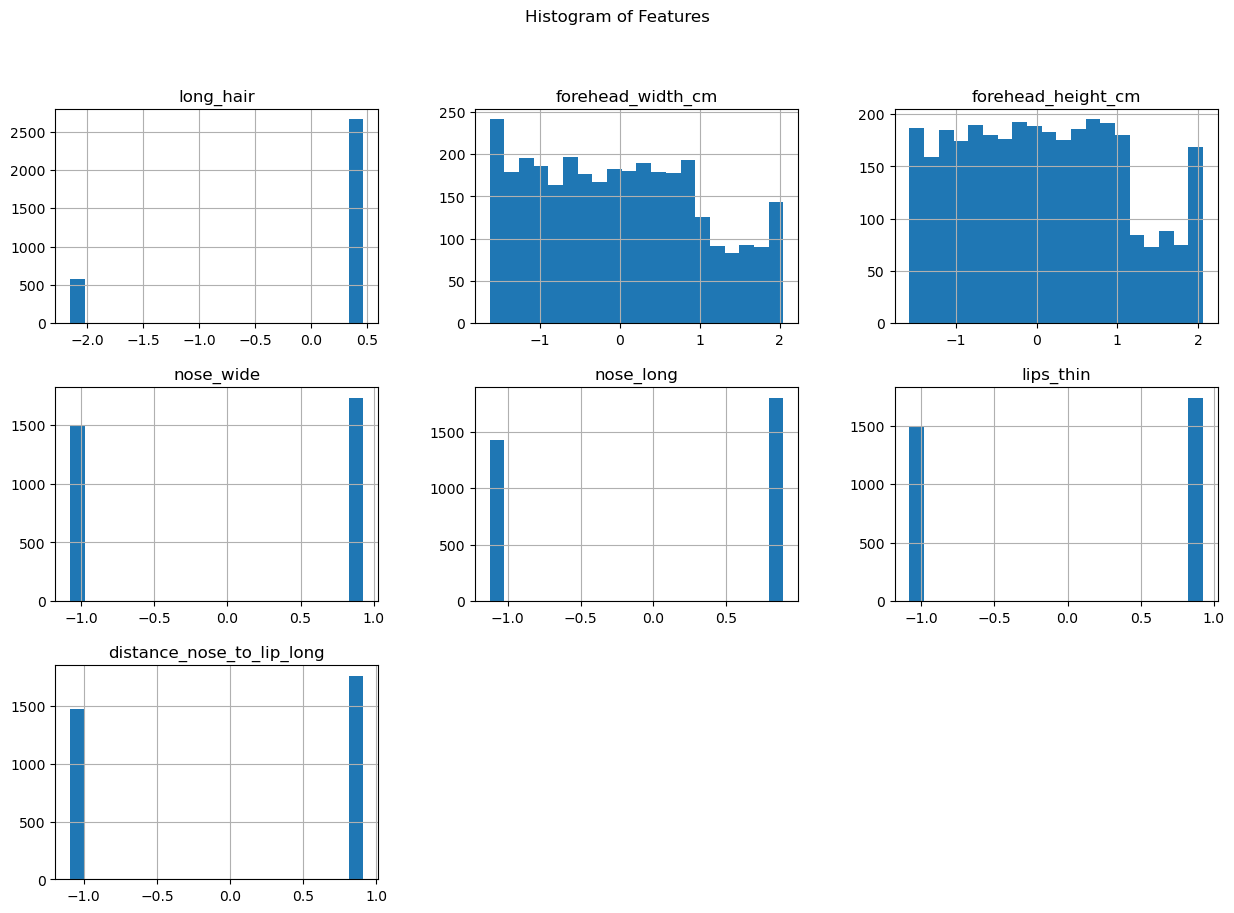

In [57]:
plt.figure(figsize=(15,10))
X_scaled.hist(figsize=(15,10), bins=20)
plt.suptitle("Histogram of Features")
plt.show()

# Boxplots

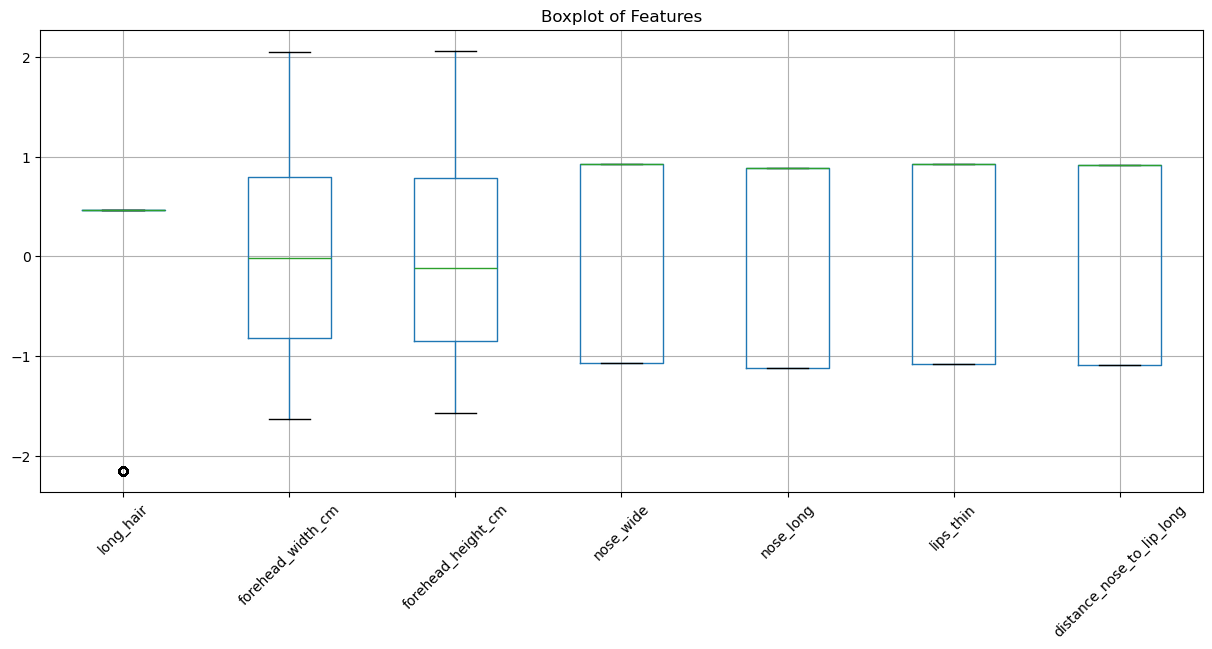

In [82]:
plt.figure(figsize=(15,6))
X_scaled.boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot of Features")
plt.show()

# Train-Test Split

In [68]:
X_train, X_test, y_train, y_test = tts(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [70]:
print("Training Data Shape :", X_train.shape)

Training Data Shape : (2586, 7)


In [72]:
print("Testing Data Shape :", X_test.shape)

Testing Data Shape : (647, 7)


In [74]:
print("Training Labels :", y_train.shape)

Training Labels : (2586,)


In [76]:
print("Testing Labels :", y_test.shape)

Testing Labels : (647,)
